In [21]:
# Section 1: Inspect available weather variables

from pathlib import Path
import pandas as pd
import numpy as np

# Define project directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load processed dataset
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dengue_weather_weekly_25_districts.csv"
)

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["week_start", "week_end"]
)

print("Dataset shape:", df.shape)

print("\nDataset date range:")
print(df["week_start"].min(), "to", df["week_start"].max())

print("\nNumber of districts:")
print(df["district_key"].nunique())

# Identify weather columns
weather_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in [
        "precipitation",
        "rain",
        "temperature",
        "humidity",
        "dew_point",
        "wind",
        "cloud",
        "radiation",
        "evapotranspiration"
    ])
]

print("\nAvailable weather variables:")
for column in weather_columns:
    print(column)

print("\nWeather variable missing-value audit:")

weather_audit = pd.DataFrame({
    "missing_values": df[weather_columns].isna().sum(),
    "missing_percentage": (
        df[weather_columns].isna().mean() * 100
    ).round(2),
    "unique_values": df[weather_columns].nunique()
})

display(weather_audit)

Dataset shape: (24775, 27)

Dataset date range:
2006-12-23 00:00:00 to 2025-12-13 00:00:00

Number of districts:
25

Available weather variables:
precipitation_sum
precipitation_hours
shortwave_radiation_sum
et0_fao_evapotranspiration
precipitation_mean_daily
shortwave_radiation_mean_daily
temperature_2m_mean
temperature_2m_max
temperature_2m_min
relative_humidity_2m_mean
relative_humidity_2m_max
relative_humidity_2m_min
dew_point_2m_mean
wind_speed_10m_mean
wind_speed_10m_max
cloud_cover_mean
wind_direction_10m_dominant

Weather variable missing-value audit:


,missing_values,missing_percentage,unique_values
precipitation_sum,0,0.0,2415
precipitation_hours,0,0.0,169
shortwave_radiation_sum,0,0.0,9493
et0_fao_evapotranspiration,0,0.0,3866
precipitation_mean_daily,0,0.0,2742
shortwave_radiation_mean_daily,0,0.0,9964
temperature_2m_mean,0,0.0,1330
temperature_2m_max,0,0.0,1713
temperature_2m_min,0,0.0,1458
relative_humidity_2m_mean,0,0.0,348


In [22]:
# Section 2: Inspect weekly rainfall measurements

# Sort data chronologically within each district
df = df.sort_values(
    ["district_key", "week_start"]
).copy()

# Check rainfall statistics
print("Weekly Rainfall Statistics")
print("=" * 40)

display(
    df["precipitation_sum"].describe()
)

# Inspect rainfall for one district
selected_district = "colombo"

rainfall_sample = df.loc[
    df["district_key"] == selected_district,
    [
        "week_start",
        "week_end",
        "precipitation_sum",
        "precipitation_hours",
        "precipitation_mean_daily"
    ]
].head(15)

print("\nRainfall observations for:", selected_district)

display(rainfall_sample)

# Check reporting period lengths
df["period_days"] = (
    df["week_end"] - df["week_start"]
).dt.days + 1

print("\nReporting period length distribution:")
display(df["period_days"].value_counts().sort_index())

Weekly Rainfall Statistics


count    24775.000000
mean        37.582490
std         47.456314
min          0.000000
25%          6.000000
50%         21.000000
75%         52.800000
max        592.200000
Name: precipitation_sum, dtype: float64


Rainfall observations for: colombo


,week_start,week_end,precipitation_sum,precipitation_hours,precipitation_mean_daily
3964,2006-12-23,2006-12-29,8.6,22.0,1.228571
3965,2006-12-30,2007-01-05,0.0,0.0,0.000000
3966,2007-01-06,2007-01-12,28.8,41.0,4.114286
3967,2007-01-13,2007-01-19,7.8,14.0,1.114286
3968,2007-01-20,2007-01-26,3.2,10.0,0.457143
3969,2007-01-27,2007-02-02,22.5,31.0,3.214286
3970,2007-02-03,2007-02-09,1.9,7.0,0.271429
3971,2007-02-10,2007-02-16,2.6,12.0,0.371429
3972,2007-02-17,2007-02-23,2.2,12.0,0.314286
3973,2007-02-24,2007-03-02,19.3,28.0,2.757143



Reporting period length distribution:


period_days
6       25
7    24725
8       25
Name: count, dtype: int64

In [23]:
# Section 3: Create accumulated rainfall features

# Ensure correct chronological order
df = df.sort_values(
    ["district_key", "week_start"]
).copy()

# Group rainfall by district
rainfall_group = df.groupby("district_key")[
    "precipitation_sum"
]

# Previous period rainfall
df["rainfall_lag_1"] = rainfall_group.shift(1)

# Accumulated rainfall over 2, 3 and 4 periods
for window in [2, 3, 4]:

    df[f"rainfall_{window}period_total"] = (
        df.groupby("district_key")["precipitation_sum"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).sum()
        )
    )

# Average rainfall over 2 and 4 periods
for window in [2, 4]:

    df[f"rainfall_{window}period_mean"] = (
        df.groupby("district_key")["precipitation_sum"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

print("Rainfall features created successfully.")

rainfall_features = [
    "rainfall_lag_1",
    "rainfall_2period_total",
    "rainfall_3period_total",
    "rainfall_4period_total",
    "rainfall_2period_mean",
    "rainfall_4period_mean"
]

display(df[rainfall_features].describe().T)

Rainfall features created successfully.


,count,mean,std,min,25%,50%,75%,max
rainfall_lag_1,24750.0,37.585745,47.478111,0.0,6.0,21.00,52.800,592.20
rainfall_2period_total,24750.0,75.191754,79.209645,0.0,17.4,49.50,107.900,768.20
rainfall_3period_total,24725.0,112.805395,107.174840,0.0,31.9,81.30,164.100,879.80
rainfall_4period_total,24700.0,150.426251,133.623337,0.0,46.4,112.80,217.700,1081.40
rainfall_2period_mean,24750.0,37.595877,39.604822,0.0,8.7,24.75,53.950,384.10
rainfall_4period_mean,24700.0,37.606563,33.405834,0.0,11.6,28.20,54.425,270.35


In [24]:
# Section 4: Create temperature features

temperature_columns = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min"
]

# Create historical temperature features
for column in temperature_columns:

    grouped_temperature = df.groupby("district_key")[column]

    # Previous reporting period
    df[f"{column}_lag_1"] = grouped_temperature.shift(1)

    # Rolling averages over 2, 3 and 4 periods
    for window in [2, 3, 4]:

        df[f"{column}_{window}period_mean"] = (
            df.groupby("district_key")[column]
            .transform(
                lambda x: x.rolling(
                    window=window,
                    min_periods=window
                ).mean()
            )
        )

print("Temperature features created successfully.")

temperature_features = [
    col for col in df.columns
    if col.startswith("temperature_2m_")
    and (
        "lag_1" in col
        or "period_mean" in col
    )
]

display(
    df[temperature_features].describe().T
)

Temperature features created successfully.


,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean_lag_1,24750.0,26.186660,3.271289,10.485714,25.428571,26.614286,28.085714,32.028571
temperature_2m_mean_2period_mean,24750.0,26.186801,3.254116,11.421429,25.464286,26.600000,28.078571,31.928571
temperature_2m_mean_3period_mean,24725.0,26.188882,3.243290,11.585714,25.485714,26.604762,28.085714,31.661905
temperature_2m_mean_4period_mean,24700.0,26.190811,3.235049,11.614286,25.496429,26.614286,28.083036,31.560714
temperature_2m_max_lag_1,24750.0,29.998392,3.531474,12.757143,28.742857,30.214286,32.057143,38.457143
temperature_2m_max_2period_mean,24750.0,29.998372,3.487215,14.064286,28.807143,30.207143,32.021429,37.985714
temperature_2m_max_3period_mean,24725.0,30.000742,3.461244,14.071429,28.838095,30.209524,32.009524,38.080952
temperature_2m_max_4period_mean,24700.0,30.003040,3.442501,14.396429,28.867857,30.203571,32.010714,37.864286
temperature_2m_min_lag_1,24750.0,23.368123,3.384297,5.657143,22.371429,24.000000,25.471429,29.785714
temperature_2m_min_2period_mean,24750.0,23.368497,3.362671,6.821429,22.371429,23.985714,25.471429,29.678571


In [25]:
# Section 5: Create humidity and dew point features

humidity_columns = [
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean"
]

for column in humidity_columns:

    grouped_humidity = df.groupby("district_key")[column]

    # Previous reporting period
    df[f"{column}_lag_1"] = grouped_humidity.shift(1)

    # Rolling averages over 2, 3 and 4 periods
    for window in [2, 3, 4]:

        df[f"{column}_{window}period_mean"] = (
            df.groupby("district_key")[column]
            .transform(
                lambda x: x.rolling(
                    window=window,
                    min_periods=window
                ).mean()
            )
        )

print("Humidity and dew point features created successfully.")

humidity_features = [
    col for col in df.columns
    if (
        col.startswith("relative_humidity_2m_")
        or col.startswith("dew_point_2m_")
    )
    and (
        "lag_1" in col
        or "period_mean" in col
    )
]

display(df[humidity_features].describe().T)

Humidity and dew point features created successfully.


,count,mean,std,min,25%,50%,75%,max
relative_humidity_2m_mean_lag_1,24750.0,80.811087,7.582596,52.428571,75.857143,82.142857,86.857143,97.571429
relative_humidity_2m_mean_2period_mean,24750.0,80.814333,7.255879,53.000000,76.071429,82.214286,86.642857,95.071429
relative_humidity_2m_mean_3period_mean,24725.0,80.813024,7.054887,53.714286,76.142857,82.142857,86.571429,94.238095
relative_humidity_2m_mean_4period_mean,24700.0,80.810291,6.908294,54.571429,76.214286,82.071429,86.464286,93.500000
relative_humidity_2m_max_lag_1,24750.0,92.199960,5.523001,65.142857,88.714286,93.571429,96.571429,100.000000
relative_humidity_2m_max_2period_mean,24750.0,92.201813,5.337270,65.642857,88.714286,93.571429,96.428571,100.000000
relative_humidity_2m_max_3period_mean,24725.0,92.200968,5.230136,66.428571,88.714286,93.476190,96.333333,100.000000
relative_humidity_2m_max_4period_mean,24700.0,92.199129,5.152489,67.642857,88.750000,93.428571,96.285714,100.000000
relative_humidity_2m_min_lag_1,24750.0,64.629026,11.273847,22.142857,56.714286,66.142857,73.857143,92.142857
relative_humidity_2m_min_2period_mean,24750.0,64.633294,10.747126,23.642857,56.928571,66.214286,73.500000,86.928571


In [26]:
# Section 6: Inspect daily and weekly weather datasets

import pandas as pd
from pathlib import Path

# File paths
daily_path = Path(
    r"C:\Users\Nethmi\Documents\GitHub\RiskWeave\data\raw\weather_era5_2006_2025\weather_daily_era5_2006-12-23_to_2025-12-19.csv"
)

weekly_audit_path = Path(
    r"C:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\weather_period_aggregation_audit.csv"
)

# Check whether both files exist
print("Daily dataset exists:", daily_path.exists())
print("Weekly audit exists:", weekly_audit_path.exists())

# Load datasets
daily_weather = pd.read_csv(daily_path)
weekly_audit = pd.read_csv(weekly_audit_path)

# --------------------------------------------------
# A. Daily weather dataset
# --------------------------------------------------

print("\n========== DAILY WEATHER DATASET ==========")

print("Shape:", daily_weather.shape)

print("\nColumns:")
print(daily_weather.columns.tolist())

print("\nData types:")
print(daily_weather.dtypes)

print("\nFirst five rows:")
display(daily_weather.head())

print("\nMissing values:")
display(
    daily_weather.isnull().sum()
    .sort_values(ascending=False)
)

# --------------------------------------------------
# B. Identify possible date columns
# --------------------------------------------------

print("\n========== POSSIBLE DATE COLUMNS ==========")

for column in daily_weather.columns:

    if any(word in column.lower() for word in ["date", "time", "day"]):

        print(f"\nColumn: {column}")

        print("First values:")
        print(daily_weather[column].head().tolist())

        print("Last values:")
        print(daily_weather[column].tail().tolist())

# --------------------------------------------------
# C. Weekly aggregation audit
# --------------------------------------------------

print("\n========== WEEKLY WEATHER AUDIT ==========")

print("Shape:", weekly_audit.shape)

print("\nColumns:")
print(weekly_audit.columns.tolist())

print("\nFirst ten rows:")
display(weekly_audit.head(10))

print("\nData types:")
print(weekly_audit.dtypes)

Daily dataset exists: True
Weekly audit exists: True

========== DAILY WEATHER DATASET ==========
Shape: (173425, 25)

Columns:
['district', 'date', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'cloud_cover_mean', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'requested_latitude', 'requested_longitude', 'era5_grid_latitude', 'era5_grid_longitude', 'era5_grid_elevation_m', 'model', 'timezone']

Data types:
district                        object
date                            object
precipitation_sum              float64
rain_sum                       float64
precipitation_hours            float64
temperature_2m_mean            float64
temperature_2m_max             float64
temperature_2m_min             float64
relative

,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,...,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
0,Ampara,2006-12-23,6.8,6.8,22.0,25.3,27.1,24.2,89,94,...,99,13.74,2.80,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
1,Ampara,2006-12-24,3.4,3.4,19.0,25.6,27.3,23.8,87,94,...,97,11.36,2.60,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
2,Ampara,2006-12-25,3.8,3.8,11.0,25.2,26.4,24.0,83,87,...,100,6.42,2.08,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
3,Ampara,2006-12-26,1.3,1.3,8.0,25.5,27.4,23.6,81,89,...,98,12.89,3.19,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
4,Ampara,2006-12-27,0.0,0.0,0.0,25.4,28.0,23.5,77,84,...,93,14.11,3.48,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo



Missing values:


district                       0
date                           0
precipitation_sum              0
rain_sum                       0
precipitation_hours            0
temperature_2m_mean            0
temperature_2m_max             0
temperature_2m_min             0
relative_humidity_2m_mean      0
relative_humidity_2m_max       0
relative_humidity_2m_min       0
dew_point_2m_mean              0
wind_speed_10m_mean            0
wind_speed_10m_max             0
wind_direction_10m_dominant    0
cloud_cover_mean               0
shortwave_radiation_sum        0
et0_fao_evapotranspiration     0
requested_latitude             0
requested_longitude            0
era5_grid_latitude             0
era5_grid_longitude            0
era5_grid_elevation_m          0
model                          0
timezone                       0
dtype: int64


========== POSSIBLE DATE COLUMNS ==========

Column: date
First values:
['2006-12-23', '2006-12-24', '2006-12-25', '2006-12-26', '2006-12-27']
Last values:
['2025-12-15', '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19']

Column: timezone
First values:
['Asia/Colombo', 'Asia/Colombo', 'Asia/Colombo', 'Asia/Colombo', 'Asia/Colombo']
Last values:
['Asia/Colombo', 'Asia/Colombo', 'Asia/Colombo', 'Asia/Colombo', 'Asia/Colombo']

========== WEEKLY WEATHER AUDIT ==========
Shape: (24775, 11)

Columns:
['district_key', 'period_id', 'week_start', 'week_end', 'reporting_period_days', 'weather_days_observed', 'weather_first_date', 'weather_last_date', 'weather_days_complete', 'weather_days_expected', 'missing_weather_days']

First ten rows:


,district_key,period_id,week_start,week_end,reporting_period_days,weather_days_observed,weather_first_date,weather_last_date,weather_days_complete,weather_days_expected,missing_weather_days
0,ampara,0,2006-12-23,2006-12-29,7,7,2006-12-23,2006-12-29,True,7,0
1,ampara,1,2006-12-30,2007-01-05,7,7,2006-12-30,2007-01-05,True,7,0
2,ampara,2,2007-01-06,2007-01-12,7,7,2007-01-06,2007-01-12,True,7,0
3,ampara,3,2007-01-13,2007-01-19,7,7,2007-01-13,2007-01-19,True,7,0
4,ampara,4,2007-01-20,2007-01-26,7,7,2007-01-20,2007-01-26,True,7,0
5,ampara,5,2007-01-27,2007-02-02,7,7,2007-01-27,2007-02-02,True,7,0
6,ampara,6,2007-02-03,2007-02-09,7,7,2007-02-03,2007-02-09,True,7,0
7,ampara,7,2007-02-10,2007-02-16,7,7,2007-02-10,2007-02-16,True,7,0
8,ampara,8,2007-02-17,2007-02-23,7,7,2007-02-17,2007-02-23,True,7,0
9,ampara,9,2007-02-24,2007-03-02,7,7,2007-02-24,2007-03-02,True,7,0



Data types:
district_key             object
period_id                 int64
week_start               object
week_end                 object
reporting_period_days     int64
weather_days_observed     int64
weather_first_date       object
weather_last_date        object
weather_days_complete      bool
weather_days_expected     int64
missing_weather_days      int64
dtype: object


In [27]:
# Section 7: Daily weather coverage and reporting-period alignment audit

import pandas as pd

# Work on copies so the original datasets remain unchanged
daily_check = daily_weather.copy()
weekly_check = weekly_audit.copy()

# Standardise district names and dates
daily_check["district_key"] = (
    daily_check["district"].astype(str).str.strip().str.lower()
)

daily_check["date"] = pd.to_datetime(daily_check["date"])

weekly_check["district_key"] = (
    weekly_check["district_key"].astype(str).str.strip().str.lower()
)

for column in [
    "week_start",
    "week_end",
    "weather_first_date",
    "weather_last_date"
]:
    weekly_check[column] = pd.to_datetime(weekly_check[column])

# --------------------------------------------------
# A. District coverage
# --------------------------------------------------

print("========== DISTRICT COVERAGE ==========")

print("Daily districts:", daily_check["district_key"].nunique())
print("Weekly districts:", weekly_check["district_key"].nunique())

print("\nDaily district record counts:")
display(
    daily_check.groupby("district_key")
    .agg(
        records=("date", "size"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        unique_dates=("date", "nunique")
    )
)

# --------------------------------------------------
# B. Duplicate district-date records
# --------------------------------------------------

print("\n========== DUPLICATE CHECK ==========")

duplicate_count = daily_check.duplicated(
    subset=["district_key", "date"]
).sum()

print("Duplicate district-date records:", duplicate_count)

# --------------------------------------------------
# C. Check daily date continuity
# --------------------------------------------------

print("\n========== DAILY DATE CONTINUITY ==========")

daily_check = daily_check.sort_values(
    ["district_key", "date"]
).reset_index(drop=True)

daily_check["date_gap_days"] = (
    daily_check.groupby("district_key")["date"]
    .diff()
    .dt.days
)

print("Date gap distribution:")
display(
    daily_check["date_gap_days"].value_counts(dropna=False).sort_index()
)

# --------------------------------------------------
# D. Compare rainfall variables
# --------------------------------------------------

print("\n========== RAINFALL VARIABLE COMPARISON ==========")

rainfall_difference = (
    daily_check["precipitation_sum"]
    - daily_check["rain_sum"]
).abs()

print("Maximum absolute difference:", rainfall_difference.max())
print("Rows with different values:", (rainfall_difference > 0.000001).sum())

# --------------------------------------------------
# E. Weekly audit completeness
# --------------------------------------------------

print("\n========== WEEKLY AUDIT COMPLETENESS ==========")

print("Complete weekly periods:", weekly_check["weather_days_complete"].sum())
print("Incomplete weekly periods:", (~weekly_check["weather_days_complete"]).sum())

print("\nReporting-period length distribution:")
display(
    weekly_check["reporting_period_days"].value_counts().sort_index()
)

print("\nMissing weather days distribution:")
display(
    weekly_check["missing_weather_days"].value_counts().sort_index()
)

# --------------------------------------------------
# F. Compare actual daily records with weekly boundaries
# --------------------------------------------------

print("\n========== REPORTING-PERIOD ALIGNMENT ==========")

# Match each daily observation to the latest reporting-period start
daily_for_alignment = daily_check.sort_values(
    ["date", "district_key"]
)

weekly_for_alignment = weekly_check.sort_values(
    ["week_start", "district_key"]
)

aligned = pd.merge_asof(
    daily_for_alignment,
    weekly_for_alignment[
        [
            "district_key",
            "period_id",
            "week_start",
            "week_end"
        ]
    ].sort_values(["week_start", "district_key"]),
    left_on="date",
    right_on="week_start",
    by="district_key",
    direction="backward"
)

# Keep observations that fall within the assigned reporting period
aligned = aligned[
    aligned["week_end"].notna()
    & (aligned["date"] <= aligned["week_end"])
].copy()

# Count actual daily observations within each district-period
actual_counts = (
    aligned.groupby(["district_key", "period_id"])
    .agg(
        actual_daily_records=("date", "nunique"),
        actual_first_date=("date", "min"),
        actual_last_date=("date", "max")
    )
    .reset_index()
)

alignment_audit = weekly_check.merge(
    actual_counts,
    on=["district_key", "period_id"],
    how="left"
)

alignment_audit["actual_daily_records"] = (
    alignment_audit["actual_daily_records"].fillna(0).astype(int)
)

alignment_audit["count_matches_expected"] = (
    alignment_audit["actual_daily_records"]
    == alignment_audit["reporting_period_days"]
)

print("Weekly periods audited:", len(alignment_audit))

print(
    "Periods with matching daily record counts:",
    alignment_audit["count_matches_expected"].sum()
)

print(
    "Periods with mismatched daily record counts:",
    (~alignment_audit["count_matches_expected"]).sum()
)

print("\nExamples of mismatched periods:")
display(
    alignment_audit.loc[
        ~alignment_audit["count_matches_expected"],
        [
            "district_key",
            "period_id",
            "week_start",
            "week_end",
            "reporting_period_days",
            "weather_days_observed",
            "actual_daily_records"
        ]
    ].head(20)
)

print("\n========== SECTION 7 COMPLETED ==========")

========== DISTRICT COVERAGE ==========
Daily districts: 25
Weekly districts: 25

Daily district record counts:


,records,first_date,last_date,unique_dates
district_key,,,,
ampara,6937,2006-12-23,2025-12-19,6937
anuradhapura,6937,2006-12-23,2025-12-19,6937
badulla,6937,2006-12-23,2025-12-19,6937
batticaloa,6937,2006-12-23,2025-12-19,6937
colombo,6937,2006-12-23,2025-12-19,6937
galle,6937,2006-12-23,2025-12-19,6937
gampaha,6937,2006-12-23,2025-12-19,6937
hambantota,6937,2006-12-23,2025-12-19,6937
jaffna,6937,2006-12-23,2025-12-19,6937



========== DUPLICATE CHECK ==========
Duplicate district-date records: 0

========== DAILY DATE CONTINUITY ==========
Date gap distribution:


date_gap_days
1.0    173400
NaN        25
Name: count, dtype: int64


========== RAINFALL VARIABLE COMPARISON ==========
Maximum absolute difference: 0.0
Rows with different values: 0

========== WEEKLY AUDIT COMPLETENESS ==========
Complete weekly periods: 24775
Incomplete weekly periods: 0

Reporting-period length distribution:


reporting_period_days
6       25
7    24725
8       25
Name: count, dtype: int64


Missing weather days distribution:


missing_weather_days
0    24775
Name: count, dtype: int64


========== REPORTING-PERIOD ALIGNMENT ==========
Weekly periods audited: 24775
Periods with matching daily record counts: 23784
Periods with mismatched daily record counts: 991

Examples of mismatched periods:


,district_key,period_id,week_start,week_end,reporting_period_days,weather_days_observed,actual_daily_records
18829,nuwaraeliya,0,2006-12-23,2006-12-29,7,7,0
18830,nuwaraeliya,1,2006-12-30,2007-01-05,7,7,0
18831,nuwaraeliya,2,2007-01-06,2007-01-12,7,7,0
18832,nuwaraeliya,3,2007-01-13,2007-01-19,7,7,0
18833,nuwaraeliya,4,2007-01-20,2007-01-26,7,7,0
18834,nuwaraeliya,5,2007-01-27,2007-02-02,7,7,0
18835,nuwaraeliya,6,2007-02-03,2007-02-09,7,7,0
18836,nuwaraeliya,7,2007-02-10,2007-02-16,7,7,0
18837,nuwaraeliya,8,2007-02-17,2007-02-23,7,7,0
18838,nuwaraeliya,9,2007-02-24,2007-03-02,7,7,0



========== SECTION 7 COMPLETED ==========


In [28]:
# Section 7B: Correct district-name matching

# Standardise district names in both datasets
daily_check["district_key"] = (
    daily_check["district"]
    .str.strip()
    .str.lower()
    .str.replace(" ", "", regex=False)
)

weekly_check["district_key"] = (
    weekly_check["district_key"]
    .str.strip()
    .str.lower()
    .str.replace(" ", "", regex=False)
)

# Rebuild daily-to-weekly alignment
daily_for_alignment = daily_check.sort_values(
    ["date", "district_key"]
).reset_index(drop=True)

weekly_for_alignment = weekly_check.sort_values(
    ["week_start", "district_key"]
).reset_index(drop=True)

aligned = pd.merge_asof(
    daily_for_alignment,
    weekly_for_alignment[
        [
            "district_key",
            "period_id",
            "week_start",
            "week_end"
        ]
    ],
    left_on="date",
    right_on="week_start",
    by="district_key",
    direction="backward"
)

# Keep observations inside their assigned reporting period
aligned = aligned[
    aligned["week_end"].notna()
    & (aligned["date"] <= aligned["week_end"])
].copy()

# Count daily observations in each reporting period
actual_counts = (
    aligned.groupby(["district_key", "period_id"])
    .agg(
        actual_daily_records=("date", "nunique")
    )
    .reset_index()
)

alignment_audit = weekly_check.merge(
    actual_counts,
    on=["district_key", "period_id"],
    how="left"
)

alignment_audit["actual_daily_records"] = (
    alignment_audit["actual_daily_records"]
    .fillna(0)
    .astype(int)
)

alignment_audit["count_matches_expected"] = (
    alignment_audit["actual_daily_records"]
    == alignment_audit["reporting_period_days"]
)

print("Total weekly periods:", len(alignment_audit))

print(
    "Matching periods:",
    alignment_audit["count_matches_expected"].sum()
)

print(
    "Mismatched periods:",
    (~alignment_audit["count_matches_expected"]).sum()
)

print("\nRemaining mismatches:")
display(
    alignment_audit.loc[
        ~alignment_audit["count_matches_expected"],
        [
            "district_key",
            "period_id",
            "week_start",
            "week_end",
            "reporting_period_days",
            "actual_daily_records"
        ]
    ].head(20)
)

Total weekly periods: 24775
Matching periods: 24775
Mismatched periods: 0

Remaining mismatches:


,district_key,period_id,week_start,week_end,reporting_period_days,actual_daily_records


In [29]:
# Section 8: Aggregate daily weather into dengue reporting periods

import pandas as pd
from pathlib import Path

# --------------------------------------------------
# A. Prepare copies of the verified datasets
# --------------------------------------------------

daily_agg = daily_check.copy()
weekly_agg = weekly_check.copy()

daily_agg["date"] = pd.to_datetime(daily_agg["date"])

weekly_agg["week_start"] = pd.to_datetime(weekly_agg["week_start"])
weekly_agg["week_end"] = pd.to_datetime(weekly_agg["week_end"])

# --------------------------------------------------
# B. Assign each daily record to its reporting period
# --------------------------------------------------

daily_agg = daily_agg.sort_values(
    ["date", "district_key"]
).reset_index(drop=True)

weekly_periods = weekly_agg[
    [
        "district_key",
        "period_id",
        "week_start",
        "week_end",
        "reporting_period_days"
    ]
].sort_values(
    ["week_start", "district_key"]
).reset_index(drop=True)

daily_period_data = pd.merge_asof(
    daily_agg,
    weekly_periods,
    left_on="date",
    right_on="week_start",
    by="district_key",
    direction="backward"
)

# Retain observations within the actual reporting-period boundaries
daily_period_data = daily_period_data[
    daily_period_data["week_end"].notna()
    & (daily_period_data["date"] <= daily_period_data["week_end"])
].copy()

print("Daily observations assigned:", len(daily_period_data))

# --------------------------------------------------
# C. Aggregate daily weather observations
# --------------------------------------------------

daily_weather_features = (
    daily_period_data
    .groupby(["district_key", "period_id"])
    .agg(
        # Rainfall
        daily_rainfall_total=("precipitation_sum", "sum"),
        daily_rainfall_mean=("precipitation_sum", "mean"),
        daily_rainfall_max=("precipitation_sum", "max"),
        daily_rainfall_std=("precipitation_sum", "std"),

        # Rainfall occurrence
        rainy_days=("precipitation_sum", lambda x: (x > 0).sum()),

        # Precipitation duration
        daily_precipitation_hours_total=("precipitation_hours", "sum"),

        # Temperature
        daily_temperature_mean=("temperature_2m_mean", "mean"),
        daily_temperature_max=("temperature_2m_max", "max"),
        daily_temperature_min=("temperature_2m_min", "min"),

        # Relative humidity
        daily_humidity_mean=("relative_humidity_2m_mean", "mean"),
        daily_humidity_max=("relative_humidity_2m_max", "max"),
        daily_humidity_min=("relative_humidity_2m_min", "min"),

        # Dew point
        daily_dew_point_mean=("dew_point_2m_mean", "mean"),

        # Wind speed
        daily_wind_speed_mean=("wind_speed_10m_mean", "mean"),
        daily_wind_speed_max=("wind_speed_10m_max", "max"),

        # Cloud cover
        daily_cloud_cover_mean=("cloud_cover_mean", "mean"),

        # Solar radiation
        daily_shortwave_radiation_total=("shortwave_radiation_sum", "sum"),
        daily_shortwave_radiation_mean=("shortwave_radiation_sum", "mean"),

        # Evapotranspiration
        daily_et0_total=("et0_fao_evapotranspiration", "sum"),
        daily_et0_mean=("et0_fao_evapotranspiration", "mean"),

        # Audit information
        daily_records_count=("date", "nunique"),
        actual_first_weather_date=("date", "min"),
        actual_last_weather_date=("date", "max")
    )
    .reset_index()
)

# --------------------------------------------------
# D. Attach reporting-period dates
# --------------------------------------------------

daily_weather_features = daily_weather_features.merge(
    weekly_periods,
    on=["district_key", "period_id"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# E. Validate aggregation completeness
# --------------------------------------------------

daily_weather_features["record_count_matches"] = (
    daily_weather_features["daily_records_count"]
    == daily_weather_features["reporting_period_days"]
)

print("\n========== AGGREGATION AUDIT ==========")

print("Aggregated rows:", len(daily_weather_features))

print(
    "Complete periods:",
    daily_weather_features["record_count_matches"].sum()
)

print(
    "Incomplete periods:",
    (~daily_weather_features["record_count_matches"]).sum()
)

print("\nReporting-period record counts:")
display(
    daily_weather_features["daily_records_count"]
    .value_counts()
    .sort_index()
)

# --------------------------------------------------
# F. Inspect the resulting features
# --------------------------------------------------

print("\n========== FEATURE DATASET ==========")

print("Shape:", daily_weather_features.shape)

print("\nColumns:")
print(daily_weather_features.columns.tolist())

display(daily_weather_features.head())

print("\nFeature descriptive statistics:")
display(
    daily_weather_features.select_dtypes(
        include="number"
    ).describe().T
)

Daily observations assigned: 173425

========== AGGREGATION AUDIT ==========
Aggregated rows: 24775
Complete periods: 24775
Incomplete periods: 0

Reporting-period record counts:


daily_records_count
6       25
7    24725
8       25
Name: count, dtype: int64


========== FEATURE DATASET ==========
Shape: (24775, 29)

Columns:
['district_key', 'period_id', 'daily_rainfall_total', 'daily_rainfall_mean', 'daily_rainfall_max', 'daily_rainfall_std', 'rainy_days', 'daily_precipitation_hours_total', 'daily_temperature_mean', 'daily_temperature_max', 'daily_temperature_min', 'daily_humidity_mean', 'daily_humidity_max', 'daily_humidity_min', 'daily_dew_point_mean', 'daily_wind_speed_mean', 'daily_wind_speed_max', 'daily_cloud_cover_mean', 'daily_shortwave_radiation_total', 'daily_shortwave_radiation_mean', 'daily_et0_total', 'daily_et0_mean', 'daily_records_count', 'actual_first_weather_date', 'actual_last_weather_date', 'week_start', 'week_end', 'reporting_period_days', 'record_count_matches']


,district_key,period_id,daily_rainfall_total,daily_rainfall_mean,daily_rainfall_max,daily_rainfall_std,rainy_days,daily_precipitation_hours_total,daily_temperature_mean,daily_temperature_max,...,daily_shortwave_radiation_mean,daily_et0_total,daily_et0_mean,daily_records_count,actual_first_weather_date,actual_last_weather_date,week_start,week_end,reporting_period_days,record_count_matches
0,ampara,0,15.3,2.185714,6.8,2.597710,4,60.0,25.342857,28.3,...,13.980000,23.42,3.345714,7,2006-12-23,2006-12-29,2006-12-23,2006-12-29,7,True
1,ampara,1,0.0,0.000000,0.0,0.000000,0,0.0,24.600000,28.8,...,20.328571,32.75,4.678571,7,2006-12-30,2007-01-05,2006-12-30,2007-01-05,7,True
2,ampara,2,77.2,11.028571,23.8,10.254709,6,115.0,24.885714,27.8,...,12.932857,19.61,2.801429,7,2007-01-06,2007-01-12,2007-01-06,2007-01-12,7,True
3,ampara,3,7.3,1.042857,3.6,1.433942,4,33.0,25.514286,28.2,...,16.884286,25.32,3.617143,7,2007-01-13,2007-01-19,2007-01-13,2007-01-19,7,True
4,ampara,4,30.1,4.300000,29.6,11.157807,2,28.0,25.085714,28.7,...,17.032857,27.83,3.975714,7,2007-01-20,2007-01-26,2007-01-20,2007-01-26,7,True



Feature descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
period_id,24775.0,495.000000,286.082686,0.000000,247.000000,495.000000,743.000000,990.000000
daily_rainfall_total,24775.0,37.582490,47.456314,0.000000,6.000000,21.000000,52.800000,592.200000
daily_rainfall_mean,24775.0,5.369492,6.780325,0.000000,0.857143,3.000000,7.542857,84.600000
daily_rainfall_max,24775.0,14.582018,19.617235,0.000000,2.700000,8.700000,19.100000,310.400000
daily_rainfall_std,24775.0,5.043150,6.878939,0.000000,0.994269,2.991575,6.523511,117.545237
rainy_days,24775.0,5.399314,1.971876,0.000000,4.000000,6.000000,7.000000,8.000000
daily_precipitation_hours_total,24775.0,50.274228,40.293566,0.000000,16.000000,40.000000,77.000000,168.000000
daily_temperature_mean,24775.0,26.184974,3.271260,10.485714,25.428571,26.614286,28.085714,32.028571
daily_temperature_max,24775.0,31.118050,3.586022,14.800000,29.800000,31.300000,33.200000,41.100000
daily_temperature_min,24775.0,22.477045,3.579332,4.000000,21.300000,23.300000,24.800000,29.300000


In [30]:
# Save daily-derived reporting-period weather features

output_path = Path(
    r"C:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\daily_derived_weather_period_features.csv"
)

daily_weather_features.to_csv(
    output_path,
    index=False
)

print("Saved successfully:")
print(output_path)

Saved successfully:
C:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\daily_derived_weather_period_features.csv


In [31]:
# Section 9: Create additional rainfall indicators

# Rainy-day proportion
daily_weather_features["rainy_day_proportion"] = (
    daily_weather_features["rainy_days"]
    / daily_weather_features["reporting_period_days"]
)

# Percentage of reporting-period days with rainfall
daily_weather_features["rainy_day_percentage"] = (
    daily_weather_features["rainy_day_proportion"] * 100
)

# Rainfall intensity on rainy days
daily_weather_features["rainfall_intensity_rainy_day"] = (
    daily_weather_features["daily_rainfall_total"]
    / daily_weather_features["rainy_days"].replace(0, float("nan"))
)

# Replace undefined intensity for periods without rain with zero.
# This represents no observed rainfall, not an observed rainy-day intensity.
daily_weather_features[
    "rainfall_intensity_rainy_day"
] = daily_weather_features[
    "rainfall_intensity_rainy_day"
].fillna(0)

print("Additional rainfall indicators created.")

display(
    daily_weather_features[
        [
            "district_key",
            "period_id",
            "daily_rainfall_total",
            "rainy_days",
            "reporting_period_days",
            "rainy_day_proportion",
            "rainy_day_percentage",
            "rainfall_intensity_rainy_day"
        ]
    ].head(10)
)

print("\nDescriptive statistics:")

display(
    daily_weather_features[
        [
            "rainy_day_proportion",
            "rainy_day_percentage",
            "rainfall_intensity_rainy_day"
        ]
    ].describe().T
)

Additional rainfall indicators created.


,district_key,period_id,daily_rainfall_total,rainy_days,reporting_period_days,rainy_day_proportion,rainy_day_percentage,rainfall_intensity_rainy_day
0,ampara,0,15.3,4,7,0.571429,57.142857,3.825000
1,ampara,1,0.0,0,7,0.000000,0.000000,0.000000
2,ampara,2,77.2,6,7,0.857143,85.714286,12.866667
3,ampara,3,7.3,4,7,0.571429,57.142857,1.825000
4,ampara,4,30.1,2,7,0.285714,28.571429,15.050000
5,ampara,5,33.8,6,7,0.857143,85.714286,5.633333
6,ampara,6,3.3,4,7,0.571429,57.142857,0.825000
7,ampara,7,8.1,6,7,0.857143,85.714286,1.350000
8,ampara,8,0.7,1,7,0.142857,14.285714,0.700000
9,ampara,9,11.5,5,7,0.714286,71.428571,2.300000



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
rainy_day_proportion,24775.0,0.771333,0.281653,0.0,0.571429,0.857143,1.00,1.0
rainy_day_percentage,24775.0,77.133343,28.165334,0.0,57.142857,85.714286,100.00,100.0
rainfall_intensity_rainy_day,24775.0,5.941283,6.913091,0.0,1.314286,3.666667,8.28,84.6


In [32]:
# Save updated daily-derived weather features

daily_weather_features.to_csv(
    output_path,
    index=False
)

print("Updated dataset saved successfully:")
print(output_path)

print("Final shape:", daily_weather_features.shape)

Updated dataset saved successfully:
C:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\daily_derived_weather_period_features.csv
Final shape: (24775, 32)


In [33]:
# Convert date columns in both datasets to datetime

date_columns = ["week_start", "week_end"]

for column in date_columns:
    daily_weather_features[column] = pd.to_datetime(
        daily_weather_features[column]
    )

    weekly_weather[column] = pd.to_datetime(
        weekly_weather[column]
    )

# Verify data types
print("Daily-derived dataset:")
print(daily_weather_features[date_columns].dtypes)

print("\nOriginal weekly dataset:")
print(weekly_weather[date_columns].dtypes)

Daily-derived dataset:
week_start    datetime64[ns]
week_end      datetime64[ns]
dtype: object

Original weekly dataset:
week_start    datetime64[ns]
week_end      datetime64[ns]
dtype: object


In [34]:
comparison = daily_weather_features.merge(
    weekly_weather,
    on=["district_key", "week_start", "week_end"],
    how="inner",
    validate="one_to_one"
)

print("Matched records:", len(comparison))

Matched records: 24775


In [35]:
# Diagnose merge-key data types

merge_keys = ["district_key", "week_start", "week_end"]

print("DAILY-DERIVED DATASET")
for col in merge_keys:
    print(col, daily_weather_features[col].dtype)

print("\nORIGINAL WEEKLY DATASET")
for col in merge_keys:
    print(col, weekly_weather[col].dtype)

print("\nFirst values")

for col in merge_keys:
    print(f"\n{col}")
    print("Daily:", repr(daily_weather_features[col].iloc[0]))
    print("Weekly:", repr(weekly_weather[col].iloc[0]))

DAILY-DERIVED DATASET
district_key object
week_start datetime64[ns]
week_end datetime64[ns]

ORIGINAL WEEKLY DATASET
district_key object
week_start datetime64[ns]
week_end datetime64[ns]

First values

district_key
Daily: 'ampara'
Weekly: 'ampara'

week_start
Daily: Timestamp('2006-12-23 00:00:00')
Weekly: Timestamp('2006-12-23 00:00:00')

week_end
Daily: Timestamp('2006-12-29 00:00:00')
Weekly: Timestamp('2006-12-29 00:00:00')


In [36]:
# Check for inconsistent district keys

print("District keys matching:",
      set(daily_weather_features["district_key"])
      == set(weekly_weather["district_key"]))

print("\nDaily district examples:")
print(daily_weather_features["district_key"].unique()[:10])

print("\nWeekly district examples:")
print(weekly_weather["district_key"].unique()[:10])

# Check date column values
print("\nDate values:")
print(daily_weather_features["week_start"].head().tolist())
print(weekly_weather["week_start"].head().tolist())

District keys matching: True

Daily district examples:
['ampara' 'anuradhapura' 'badulla' 'batticaloa' 'colombo' 'galle'
 'gampaha' 'hambantota' 'jaffna' 'kalutara']

Weekly district examples:
['ampara' 'anuradhapura' 'badulla' 'batticaloa' 'colombo' 'galle'
 'gampaha' 'hambantota' 'jaffna' 'kalutara']

Date values:
[Timestamp('2006-12-23 00:00:00'), Timestamp('2006-12-30 00:00:00'), Timestamp('2007-01-06 00:00:00'), Timestamp('2007-01-13 00:00:00'), Timestamp('2007-01-20 00:00:00')]
[Timestamp('2006-12-23 00:00:00'), Timestamp('2006-12-30 00:00:00'), Timestamp('2007-01-06 00:00:00'), Timestamp('2007-01-13 00:00:00'), Timestamp('2007-01-20 00:00:00')]


In [38]:
# Section 10: Final date and key standardisation

# Standardise district keys
for data in [daily_weather_features, weekly_weather]:

    data["district_key"] = (
        data["district_key"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "", regex=False)
    )

# Convert date columns in BOTH datasets
for column in ["week_start", "week_end"]:

    daily_weather_features[column] = pd.to_datetime(
        daily_weather_features[column],
        errors="raise"
    )

    weekly_weather[column] = pd.to_datetime(
        weekly_weather[column],
        errors="raise"
    )

# Confirm data types
print("Daily-derived:")
print(daily_weather_features[
    ["district_key", "week_start", "week_end"]
].dtypes)

print("\nOriginal weekly:")
print(weekly_weather[
    ["district_key", "week_start", "week_end"]
].dtypes)

# Merge
comparison = daily_weather_features.merge(
    weekly_weather,
    on=["district_key", "week_start", "week_end"],
    how="inner",
    validate="one_to_one"
)

print("\nMatched records:", len(comparison))
print("Comparison successful!")

Daily-derived:
district_key            object
week_start      datetime64[ns]
week_end        datetime64[ns]
dtype: object

Original weekly:
district_key            object
week_start      datetime64[ns]
week_end        datetime64[ns]
dtype: object

Matched records: 24775
Comparison successful!


In [40]:
# Section 10: Compare daily-derived and original weekly weather

# Standardise district keys
for data in [daily_weather_features, weekly_weather]:

    data["district_key"] = (
        data["district_key"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "", regex=False)
    )

# Standardise date columns
for column in ["week_start", "week_end"]:

    daily_weather_features[column] = pd.to_datetime(
        daily_weather_features[column]
    )

    weekly_weather[column] = pd.to_datetime(
        weekly_weather[column]
    )

# Merge ONCE
comparison = daily_weather_features.merge(
    weekly_weather,
    on=["district_key", "week_start", "week_end"],
    how="inner",
    validate="one_to_one"
)

print("Matched records:", len(comparison))

# Define comparable weather variables
comparison_columns = {
    "daily_rainfall_total": "precipitation_sum",
    "daily_precipitation_hours_total": "precipitation_hours",
    "daily_temperature_mean": "temperature_2m_mean",
    "daily_humidity_mean": "relative_humidity_2m_mean",
    "daily_dew_point_mean": "dew_point_2m_mean",
    "daily_wind_speed_mean": "wind_speed_10m_mean",
    "daily_cloud_cover_mean": "cloud_cover_mean",
    "daily_shortwave_radiation_total": "shortwave_radiation_sum",
    "daily_et0_total": "et0_fao_evapotranspiration"
}

# Calculate comparison statistics
comparison_results = []

for daily_column, weekly_column in comparison_columns.items():

    difference = (
        comparison[daily_column] - comparison[weekly_column]
    ).abs()

    comparison_results.append({
        "daily_feature": daily_column,
        "weekly_feature": weekly_column,
        "mean_absolute_difference": difference.mean(),
        "maximum_absolute_difference": difference.max(),
        "exact_matches": (difference < 0.000001).sum()
    })

comparison_results = pd.DataFrame(comparison_results)

print("\n========== WEATHER COMPARISON RESULTS ==========")

display(comparison_results)

Matched records: 24775

========== WEATHER COMPARISON RESULTS ==========


,daily_feature,weekly_feature,mean_absolute_difference,maximum_absolute_difference,exact_matches
0,daily_rainfall_total,precipitation_sum,4.176791e-16,5.684342e-14,24775
1,daily_precipitation_hours_total,precipitation_hours,0.000000e+00,0.000000e+00,24775
2,daily_temperature_mean,temperature_2m_mean,5.930271e-16,3.552714e-15,24775
3,daily_humidity_mean,relative_humidity_2m_mean,6.441489e-16,1.421085e-14,24775
4,daily_dew_point_mean,dew_point_2m_mean,5.833477e-16,3.552714e-15,24775
5,daily_wind_speed_mean,wind_speed_10m_mean,2.745466e-16,7.105427e-15,24775
6,daily_cloud_cover_mean,cloud_cover_mean,2.097643e-15,1.421085e-14,24775
7,daily_shortwave_radiation_total,shortwave_radiation_sum,1.066316e-15,2.842171e-14,24775
8,daily_et0_total,et0_fao_evapotranspiration,3.589639e-16,7.105427e-15,24775


In [41]:
# Investigate ET0 differences

et0_difference = (
    comparison["daily_et0_total"]
    - comparison["et0_fao_evapotranspiration"]
).abs()

print("ET0 comparison")
print("Mean absolute difference:", et0_difference.mean())
print("Maximum absolute difference:", et0_difference.max())
print("Minimum absolute difference:", et0_difference.min())
print("Exact matches:", (et0_difference < 0.000001).sum())

print("\nET0 daily-derived statistics:")
display(comparison["daily_et0_total"].describe())

print("\nET0 original weekly statistics:")
display(comparison["et0_fao_evapotranspiration"].describe())

print("\nFirst 10 ET0 comparisons:")
display(
    comparison[
        [
            "district_key",
            "week_start",
            "daily_et0_total",
            "et0_fao_evapotranspiration"
        ]
    ].head(10)
)

ET0 comparison
Mean absolute difference: 3.5896389571977213e-16
Maximum absolute difference: 7.105427357601002e-15
Minimum absolute difference: 0.0
Exact matches: 24775

ET0 daily-derived statistics:


count    24775.000000
mean        29.141592
std          7.517870
min          5.560000
25%         23.770000
50%         28.610000
75%         34.350000
max         54.660000
Name: daily_et0_total, dtype: float64


ET0 original weekly statistics:


count    24775.000000
mean        29.141592
std          7.517870
min          5.560000
25%         23.770000
50%         28.610000
75%         34.350000
max         54.660000
Name: et0_fao_evapotranspiration, dtype: float64


First 10 ET0 comparisons:


,district_key,week_start,daily_et0_total,et0_fao_evapotranspiration
0,ampara,2006-12-23,23.42,23.42
1,ampara,2006-12-30,32.75,32.75
2,ampara,2007-01-06,19.61,19.61
3,ampara,2007-01-13,25.32,25.32
4,ampara,2007-01-20,27.83,27.83
5,ampara,2007-01-27,25.34,25.34
6,ampara,2007-02-03,30.81,30.81
7,ampara,2007-02-10,28.75,28.75
8,ampara,2007-02-17,32.97,32.97
9,ampara,2007-02-24,28.85,28.85


### Section 10 – Daily and Weekly Weather Comparison: Findings

All 24,775 district-reporting-period records were successfully matched
between the daily-derived weather dataset and the original weekly dataset.

Nine corresponding weather variables were compared.

All nine variables matched across all 24,775 records. The maximum
absolute differences were negligible and attributable to floating-point
precision.

This confirms that the daily aggregation procedure reproduces the
corresponding original weekly weather measurements.

Consequently, these nine equivalent variables will not be treated as
new predictive information in the daily-derived feature experiment.

The daily dataset remains useful for constructing additional features
that describe within-period weather behaviour, including rainy-day
frequency, daily rainfall extremes, and rainfall variability.

All experimental features will use observations from the completed
forecast-origin reporting period only. No weather observations from
the target reporting period will be used.

In [42]:
# Section 11: Select additional daily-derived weather features

daily_experimental_features = [
    "district_key",
    "period_id",
    "week_start",
    "week_end",
    "reporting_period_days",

    # Rainfall behaviour within the reporting period
    "rainy_days",
    "rainy_day_proportion",
    "daily_rainfall_max",
    "daily_rainfall_std",
    "rainfall_intensity_rainy_day"
]

daily_experiment = daily_weather_features[
    daily_experimental_features
].copy()

print("Daily experimental dataset shape:", daily_experiment.shape)

print("\nMissing values:")
display(daily_experiment.isnull().sum())

print("\nDescriptive statistics:")
display(daily_experiment.describe())

print("\nDuplicate district-period records:",
      daily_experiment.duplicated(
          subset=["district_key", "period_id"]
      ).sum())

Daily experimental dataset shape: (24775, 10)

Missing values:


district_key                    0
period_id                       0
week_start                      0
week_end                        0
reporting_period_days           0
rainy_days                      0
rainy_day_proportion            0
daily_rainfall_max              0
daily_rainfall_std              0
rainfall_intensity_rainy_day    0
dtype: int64


Descriptive statistics:


,period_id,week_start,week_end,reporting_period_days,rainy_days,rainy_day_proportion,daily_rainfall_max,daily_rainfall_std,rainfall_intensity_rainy_day
count,24775.000000,24775,24775,24775.000000,24775.000000,24775.000000,24775.000000,24775.000000,24775.000000
mean,495.000000,2016-06-18 00:07:15.923309568,2016-06-24 00:07:15.923309568,7.000000,5.399314,0.771333,14.582018,5.043150,5.941283
min,0.000000,2006-12-23 00:00:00,2006-12-29 00:00:00,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,247.000000,2011-09-17 00:00:00,2011-09-23 00:00:00,7.000000,4.000000,0.571429,2.700000,0.994269,1.314286
50%,495.000000,2016-06-18 00:00:00,2016-06-24 00:00:00,7.000000,6.000000,0.857143,8.700000,2.991575,3.666667
75%,743.000000,2021-03-20 00:00:00,2021-03-26 00:00:00,7.000000,7.000000,1.000000,19.100000,6.523511,8.280000
max,990.000000,2025-12-13 00:00:00,2025-12-19 00:00:00,8.000000,8.000000,1.000000,310.400000,117.545237,84.600000
std,286.082686,NaN,NaN,0.044925,1.971876,0.281653,19.617235,6.878939,6.913091



Duplicate district-period records: 0


In [44]:
from pathlib import Path

# Create the output directory if it does not exist
output_dir = Path("outputs/forecasting")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the correlation heatmap
plt.savefig(
    output_dir / "daily_weather_feature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

print("Correlation heatmap saved successfully.")

Correlation heatmap saved successfully.


<Figure size 640x480 with 0 Axes>

Spearman correlation matrix:


,rainy_days,rainy_day_proportion,daily_rainfall_max,daily_rainfall_std,rainfall_intensity_rainy_day
rainy_days,1.000000,0.999482,0.625992,0.579071,0.612086
rainy_day_proportion,0.999482,1.000000,0.626981,0.580065,0.612988
daily_rainfall_max,0.625992,0.626981,1.000000,0.992027,0.969073
daily_rainfall_std,0.579071,0.580065,0.992027,1.000000,0.954482
rainfall_intensity_rainy_day,0.612086,0.612988,0.969073,0.954482,1.000000


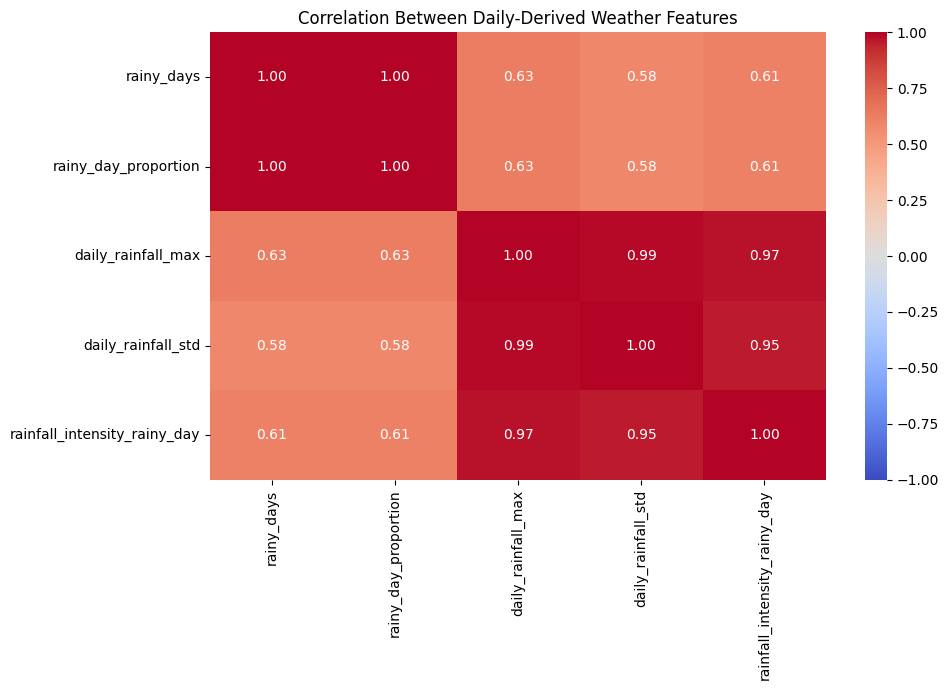

In [45]:
# Section 12: Correlation analysis of daily-derived features

import matplotlib.pyplot as plt
import seaborn as sns

correlation_features = [
    "rainy_days",
    "rainy_day_proportion",
    "daily_rainfall_max",
    "daily_rainfall_std",
    "rainfall_intensity_rainy_day"
]

correlation_matrix = daily_experiment[
    correlation_features
].corr(method="spearman")

print("Spearman correlation matrix:")
display(correlation_matrix)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Daily-Derived Weather Features")
plt.tight_layout()

plt.savefig(
    "outputs/forecasting/daily_weather_feature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Section 12 – Correlation Analysis Findings

Spearman correlation analysis was conducted on five daily-derived
weather features.

The analysis identified very strong correlations between:

- rainy_days and rainy_day_proportion (0.999482)
- daily_rainfall_max and daily_rainfall_std (0.992027)
- daily_rainfall_max and rainfall_intensity_rainy_day (0.969073)
- daily_rainfall_std and rainfall_intensity_rainy_day (0.954482)

To reduce redundant predictors in the initial experiment, the selected
features are:

- rainy_day_proportion
- daily_rainfall_max
- daily_rainfall_std

The remaining correlated features are excluded from the primary
experimental feature set. These decisions will be evaluated through
controlled forecasting experiments.

In [47]:
# Section 13A: Identify existing forecasting dataframes

import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataFrame: {name}")
        print("Shape:", obj.shape)
        print("Columns:", list(obj.columns))


DataFrame: df
Shape: (24775, 62)
Columns: ['district_key', 'week_start', 'week_end', 'dengue_cases', 'reporting_period_days', 'source_reporting_rows', 'source_areas', 'weather_days_observed', 'weather_days_expected', 'weather_days_complete', 'precipitation_sum', 'precipitation_hours', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'precipitation_mean_daily', 'shortwave_radiation_mean_daily', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'cloud_cover_mean', 'wind_direction_10m_dominant', 'period_days', 'rainfall_lag_1', 'rainfall_2period_total', 'rainfall_3period_total', 'rainfall_4period_total', 'rainfall_2period_mean', 'rainfall_4period_mean', 'temperature_2m_mean_lag_1', 'temperature_2m_mean_2period_mean', 'temperature_2m_mean_3period_mean', 'temperature_2m_mean_4period_mean', 'temperature_2m_max_lag_1',

In [48]:
# Section 13A: Inspect the dengue forecasting variables

print("Main dataframe shape:", df.shape)

print("\nDengue-related columns:")
print([
    column for column in df.columns
    if "dengue" in column.lower()
])

print("\nDate range:")
print(df["week_start"].min(), "to", df["week_start"].max())

print("\nNumber of districts:")
print(df["district_key"].nunique())

print("\nDuplicate district-week records:")
print(
    df.duplicated(
        subset=["district_key", "week_start"]
    ).sum()
)

Main dataframe shape: (24775, 62)

Dengue-related columns:
['dengue_cases']

Date range:
2006-12-23 00:00:00 to 2025-12-13 00:00:00

Number of districts:
25

Duplicate district-week records:
0


In [49]:
# Section 13B: Recreate dengue forecasting predictors

import numpy as np
import pandas as pd

# Create a separate working dataframe
forecast_experiment = df[
    ["district_key", "week_start", "week_end", "dengue_cases"]
].copy()

# Ensure dates are datetime
forecast_experiment["week_start"] = pd.to_datetime(
    forecast_experiment["week_start"]
)

forecast_experiment["week_end"] = pd.to_datetime(
    forecast_experiment["week_end"]
)

# Sort chronologically within districts
forecast_experiment = forecast_experiment.sort_values(
    ["district_key", "week_start"]
).reset_index(drop=True)

# Group dengue observations by district
district_groups = forecast_experiment.groupby(
    "district_key",
    sort=False
)["dengue_cases"]

# Current period dengue cases
forecast_experiment["dengue_current_period"] = (
    forecast_experiment["dengue_cases"]
)

# Historical dengue lags
for lag in [1, 2, 3, 4, 51, 52]:
    forecast_experiment[f"dengue_lag_{lag}"] = (
        district_groups.shift(lag)
    )

# Four-period rolling mean, including current period
forecast_experiment["dengue_rolling_mean_4"] = (
    forecast_experiment.groupby(
        "district_key",
        sort=False
    )["dengue_cases"]
    .transform(
        lambda series: series.rolling(
            window=4,
            min_periods=4
        ).mean()
    )
)

# Calendar features
week_number = forecast_experiment["week_start"].dt.isocalendar().week.astype(int)

forecast_experiment["month"] = (
    forecast_experiment["week_start"].dt.month
)

forecast_experiment["week_sin"] = np.sin(
    2 * np.pi * week_number / 52.0
)

forecast_experiment["week_cos"] = np.cos(
    2 * np.pi * week_number / 52.0
)

print("Forecasting dataframe shape:",
      forecast_experiment.shape)

print("\nMissing values:")
display(forecast_experiment.isnull().sum())

print("\nFirst five records:")
display(forecast_experiment.head())

Forecasting dataframe shape: (24775, 15)

Missing values:


district_key                0
week_start                  0
week_end                    0
dengue_cases                0
dengue_current_period       0
dengue_lag_1               25
dengue_lag_2               50
dengue_lag_3               75
dengue_lag_4              100
dengue_lag_51            1275
dengue_lag_52            1300
dengue_rolling_mean_4      75
month                       0
week_sin                    0
week_cos                    0
dtype: int64


First five records:


,district_key,week_start,week_end,dengue_cases,dengue_current_period,dengue_lag_1,dengue_lag_2,dengue_lag_3,dengue_lag_4,dengue_lag_51,dengue_lag_52,dengue_rolling_mean_4,month,week_sin,week_cos
0,ampara,2006-12-23,2006-12-29,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,-1.205367e-01,0.992709
1,ampara,2006-12-30,2007-01-05,0,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,12,6.432491e-16,1.000000
2,ampara,2007-01-06,2007-01-12,0,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1,1.205367e-01,0.992709
3,ampara,2007-01-13,2007-01-19,0,0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1,2.393157e-01,0.970942
4,ampara,2007-01-20,2007-01-26,0,0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,1,3.546049e-01,0.935016


In [50]:
# Section 13C: Forecasting feature validation

# Check chronological ordering
print(
    "Chronologically sorted:",
    forecast_experiment.equals(
        forecast_experiment.sort_values(
            ["district_key", "week_start"]
        ).reset_index(drop=True)
    )
)

# Check district count
print(
    "\nNumber of districts:",
    forecast_experiment["district_key"].nunique()
)

# Check records per district
print("\nRecords per district:")
display(
    forecast_experiment.groupby("district_key").size().describe()
)

# Verify current-period dengue cases
print(
    "\nCurrent-period dengue values match original:",
    (
        forecast_experiment["dengue_current_period"]
        == forecast_experiment["dengue_cases"]
    ).all()
)

# Verify lag 1 manually for a district
district_name = "ampara"

sample = forecast_experiment[
    forecast_experiment["district_key"] == district_name
].head(6)

display(
    sample[
        [
            "week_start",
            "dengue_cases",
            "dengue_lag_1",
            "dengue_rolling_mean_4"
        ]
    ]
)

Chronologically sorted: True

Number of districts: 25

Records per district:


count     25.0
mean     991.0
std        0.0
min      991.0
25%      991.0
50%      991.0
75%      991.0
max      991.0
dtype: float64


Current-period dengue values match original: True


,week_start,dengue_cases,dengue_lag_1,dengue_rolling_mean_4
0,2006-12-23,0,NaN,NaN
1,2006-12-30,0,0.0,NaN
2,2007-01-06,0,0.0,NaN
3,2007-01-13,0,0.0,0.0
4,2007-01-20,0,0.0,0.0
5,2007-01-27,0,0.0,0.0


In [51]:
# Section 13D: Correct predictors to match Notebook 06

forecast_experiment["dengue_rolling_mean_4"] = (
    forecast_experiment.groupby(
        "district_key", sort=False
    )["dengue_cases"]
    .transform(
        lambda s: s.rolling(
            window=4,
            min_periods=2
        ).mean()
    )
)

week_of_year = (
    forecast_experiment["week_start"]
    .dt.isocalendar()
    .week.astype(int)
)

forecast_experiment["week_sin"] = np.sin(
    2 * np.pi * week_of_year / 52.1775
)

forecast_experiment["week_cos"] = np.cos(
    2 * np.pi * week_of_year / 52.1775
)

print("Corrected rolling mean and calendar features.")

display(
    forecast_experiment[
        [
            "district_key",
            "week_start",
            "dengue_cases",
            "dengue_rolling_mean_4",
            "week_sin",
            "week_cos"
        ]
    ].head(6)
)

Corrected rolling mean and calendar features.


,district_key,week_start,dengue_cases,dengue_rolling_mean_4,week_sin,week_cos
0,ampara,2006-12-23,0,NaN,-0.141319,0.989964
1,ampara,2006-12-30,0,0.0,-0.021373,0.999772
2,ampara,2007-01-06,0,0.0,0.120129,0.992758
3,ampara,2007-01-13,0,0.0,0.238517,0.971138
4,ampara,2007-01-20,0,0.0,0.353452,0.935453
5,ampara,2007-01-27,0,0.0,0.463267,0.886219


In [52]:
# Section 13E: Create next-period dengue target

forecast_experiment["target_next_period"] = (
    forecast_experiment.groupby(
        "district_key",
        sort=False
    )["dengue_cases"].shift(-1)
)

forecast_experiment["target_week_start"] = (
    forecast_experiment.groupby(
        "district_key",
        sort=False
    )["week_start"].shift(-1)
)

print("Forecasting dataset shape:",
      forecast_experiment.shape)

print("\nTarget missing values:")
print(
    forecast_experiment["target_next_period"].isnull().sum()
)

print("\nTarget date missing values:")
print(
    forecast_experiment["target_week_start"].isnull().sum()
)

print("\nSample forecasting records:")

display(
    forecast_experiment[
        [
            "district_key",
            "week_start",
            "dengue_cases",
            "target_week_start",
            "target_next_period"
        ]
    ].head(8)
)

Forecasting dataset shape: (24775, 17)

Target missing values:
25

Target date missing values:
25

Sample forecasting records:


,district_key,week_start,dengue_cases,target_week_start,target_next_period
0,ampara,2006-12-23,0,2006-12-30,0.0
1,ampara,2006-12-30,0,2007-01-06,0.0
2,ampara,2007-01-06,0,2007-01-13,0.0
3,ampara,2007-01-13,0,2007-01-20,0.0
4,ampara,2007-01-20,0,2007-01-27,0.0
5,ampara,2007-01-27,0,2007-02-03,0.0
6,ampara,2007-02-03,0,2007-02-10,0.0
7,ampara,2007-02-10,0,2007-02-17,0.0


In [53]:
# Section 13F: Merge selected daily-derived weather features

selected_daily_features = [
    "rainy_day_proportion",
    "daily_rainfall_max",
    "daily_rainfall_std"
]

# Prepare weather features
daily_weather_selected = daily_experiment[
    [
        "district_key",
        "week_start",
        *selected_daily_features
    ]
].copy()

# Ensure matching date types
forecast_experiment["week_start"] = pd.to_datetime(
    forecast_experiment["week_start"]
)

daily_weather_selected["week_start"] = pd.to_datetime(
    daily_weather_selected["week_start"]
)

# Merge using forecast-origin district and date
forecast_experiment = forecast_experiment.merge(
    daily_weather_selected,
    on=["district_key", "week_start"],
    how="left",
    validate="one_to_one"
)

print("Merged forecasting dataset shape:",
      forecast_experiment.shape)

print("\nMissing values in selected weather features:")
display(
    forecast_experiment[selected_daily_features].isnull().sum()
)

print("\nDuplicate district-week records:",
      forecast_experiment.duplicated(
          subset=["district_key", "week_start"]
      ).sum()
)

print("\nSample merged records:")

display(
    forecast_experiment[
        [
            "district_key",
            "week_start",
            "target_week_start",
            "target_next_period",
            *selected_daily_features
        ]
    ].head()
)

Merged forecasting dataset shape: (24775, 20)

Missing values in selected weather features:


rainy_day_proportion    0
daily_rainfall_max      0
daily_rainfall_std      0
dtype: int64


Duplicate district-week records: 0

Sample merged records:


,district_key,week_start,target_week_start,target_next_period,rainy_day_proportion,daily_rainfall_max,daily_rainfall_std
0,ampara,2006-12-23,2006-12-30,0.0,0.571429,6.8,2.597710
1,ampara,2006-12-30,2007-01-06,0.0,0.000000,0.0,0.000000
2,ampara,2007-01-06,2007-01-13,0.0,0.857143,23.8,10.254709
3,ampara,2007-01-13,2007-01-20,0.0,0.571429,3.6,1.433942
4,ampara,2007-01-20,2007-01-27,0.0,0.285714,29.6,11.157807


In [54]:
# Section 13G: Prepare final experimental dataset

# Remove records without a next-period target
forecast_experiment_final = (
    forecast_experiment
    .dropna(subset=["target_next_period", "target_week_start"])
    .copy()
)

# Convert target to integer
forecast_experiment_final["target_next_period"] = (
    forecast_experiment_final["target_next_period"].astype(int)
)

# Sort chronologically
forecast_experiment_final = (
    forecast_experiment_final
    .sort_values(["target_week_start", "district_key"])
    .reset_index(drop=True)
)

print("Final experimental dataset shape:",
      forecast_experiment_final.shape)

print("\nNumber of districts:",
      forecast_experiment_final["district_key"].nunique())

print("\nTarget date range:")
print(
    forecast_experiment_final["target_week_start"].min(),
    "to",
    forecast_experiment_final["target_week_start"].max()
)

print("\nMissing target values:",
      forecast_experiment_final["target_next_period"].isnull().sum())

print("\nMissing selected weather features:")
display(
    forecast_experiment_final[
        [
            "rainy_day_proportion",
            "daily_rainfall_max",
            "daily_rainfall_std"
        ]
    ].isnull().sum()
)

print("\nDuplicate district-target dates:",
      forecast_experiment_final.duplicated(
          subset=["district_key", "target_week_start"]
      ).sum())

Final experimental dataset shape: (24750, 20)

Number of districts: 25

Target date range:
2006-12-30 00:00:00 to 2025-12-13 00:00:00

Missing target values: 0

Missing selected weather features:


rainy_day_proportion    0
daily_rainfall_max      0
daily_rainfall_std      0
dtype: int64


Duplicate district-target dates: 0


In [55]:
# Section 14: Chronological train-validation-test split

# Original Notebook 06 split boundaries
train_end = pd.Timestamp("2020-04-04")
validation_end = pd.Timestamp("2023-02-04")
test_start = pd.Timestamp("2023-02-11")

# Split using target dates, not forecast-origin dates
train_data = forecast_experiment_final[
    forecast_experiment_final["target_week_start"] <= train_end
].copy()

validation_data = forecast_experiment_final[
    (
        forecast_experiment_final["target_week_start"] > train_end
    ) &
    (
        forecast_experiment_final["target_week_start"] <= validation_end
    )
].copy()

test_data = forecast_experiment_final[
    forecast_experiment_final["target_week_start"] >= test_start
].copy()

# Display split information
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Records": [
        len(train_data),
        len(validation_data),
        len(test_data)
    ],
    "First target date": [
        train_data["target_week_start"].min(),
        validation_data["target_week_start"].min(),
        test_data["target_week_start"].min()
    ],
    "Last target date": [
        train_data["target_week_start"].max(),
        validation_data["target_week_start"].max(),
        test_data["target_week_start"].max()
    ]
})

display(split_summary)

print("\nTotal split records:",
      len(train_data) + len(validation_data) + len(test_data))

print("Original experimental records:",
      len(forecast_experiment_final))

,Dataset,Records,First target date,Last target date
0,Training,17325,2006-12-30,2020-04-04
1,Validation,3700,2020-04-11,2023-02-04
2,Testing,3725,2023-02-11,2025-12-13



Total split records: 24750
Original experimental records: 24750


In [65]:
# Create chronological split masks using the target period date

train_mask = (
    experiment_A["target_week_start"] <= pd.Timestamp("2020-04-04")
)

valid_mask = (
    (experiment_A["target_week_start"] >= pd.Timestamp("2020-04-11")) &
    (experiment_A["target_week_start"] <= pd.Timestamp("2023-02-04"))
)

test_mask = (
    (experiment_A["target_week_start"] >= pd.Timestamp("2023-02-11")) &
    (experiment_A["target_week_start"] <= pd.Timestamp("2025-12-13"))
)

# Apply identical masks to all three experiments
train_A = experiment_A.loc[train_mask].copy()
valid_A = experiment_A.loc[valid_mask].copy()
test_A = experiment_A.loc[test_mask].copy()

train_B = experiment_B.loc[train_mask].copy()
valid_B = experiment_B.loc[valid_mask].copy()
test_B = experiment_B.loc[test_mask].copy()

train_C = experiment_C.loc[train_mask].copy()
valid_C = experiment_C.loc[valid_mask].copy()
test_C = experiment_C.loc[test_mask].copy()

print("Experiment A:", len(train_A), len(valid_A), len(test_A))
print("Experiment B:", len(train_B), len(valid_B), len(test_B))
print("Experiment C:", len(train_C), len(valid_C), len(test_C))

Experiment A: 17325 3700 3725
Experiment B: 17325 3700 3725
Experiment C: 17325 3700 3725


In [66]:
for name, train_df, valid_df, test_df in [
    ("A", train_A, valid_A, test_A),
    ("B", train_B, valid_B, test_B),
    ("C", train_C, valid_C, test_C)
]:
    print(f"\nExperiment {name}")
    print("Train:", train_df["target_week_start"].min(),
          "to", train_df["target_week_start"].max())
    print("Validation:", valid_df["target_week_start"].min(),
          "to", valid_df["target_week_start"].max())
    print("Test:", test_df["target_week_start"].min(),
          "to", test_df["target_week_start"].max())


Experiment A
Train: 2006-12-30 00:00:00 to 2020-04-04 00:00:00
Validation: 2020-04-11 00:00:00 to 2023-02-04 00:00:00
Test: 2023-02-11 00:00:00 to 2025-12-13 00:00:00

Experiment B
Train: 2006-12-30 00:00:00 to 2020-04-04 00:00:00
Validation: 2020-04-11 00:00:00 to 2023-02-04 00:00:00
Test: 2023-02-11 00:00:00 to 2025-12-13 00:00:00

Experiment C
Train: 2006-12-30 00:00:00 to 2020-04-04 00:00:00
Validation: 2020-04-11 00:00:00 to 2023-02-04 00:00:00
Test: 2023-02-11 00:00:00 to 2025-12-13 00:00:00


In [56]:
# Section 15A: Define forecasting experiment predictors

# Original 12 predictors from Notebook 06
base_features = [
    "district_key",
    "dengue_current_period",
    "dengue_lag_1",
    "dengue_lag_2",
    "dengue_lag_3",
    "dengue_lag_4",
    "dengue_lag_51",
    "dengue_lag_52",
    "dengue_rolling_mean_4",
    "month",
    "week_sin",
    "week_cos"
]

# Three selected daily-derived weather features
daily_weather_features_selected = [
    "rainy_day_proportion",
    "daily_rainfall_max",
    "daily_rainfall_std"
]

# Original weekly weather predictors from Notebook 06
weekly_weather_features = [
    # Use the exact original 28 weather predictors
    # from Notebook 06 here.
]

print("Base predictors:", len(base_features))
print("Daily-derived weather predictors:",
      len(daily_weather_features_selected))

Base predictors: 12
Daily-derived weather predictors: 3


In [57]:
weekly_weather_base = [
    "precipitation_mean_daily",
    "precipitation_hours",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "cloud_cover_mean",
    "shortwave_radiation_mean_daily",
    "et0_fao_evapotranspiration"
]

In [58]:
# Section 15A: Define forecasting experiment predictors

# Original 12 predictors
base_features = [
    "district_key",
    "dengue_current_period",
    "dengue_lag_1",
    "dengue_lag_2",
    "dengue_lag_3",
    "dengue_lag_4",
    "dengue_lag_51",
    "dengue_lag_52",
    "dengue_rolling_mean_4",
    "month",
    "week_sin",
    "week_cos"
]

# Original weekly weather variables from Notebook 06
weekly_weather_base = [
    "precipitation_mean_daily",
    "precipitation_hours",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "cloud_cover_mean",
    "shortwave_radiation_mean_daily",
    "et0_fao_evapotranspiration"
]

# Generate current-period and previous-period weather predictors
weekly_weather_features = []

for feature in weekly_weather_base:
    weekly_weather_features.extend([
        f"{feature}_lag0",
        f"{feature}_lag1"
    ])

# Three selected daily-derived features
daily_weather_features_selected = [
    "rainy_day_proportion",
    "daily_rainfall_max",
    "daily_rainfall_std"
]

print("Base predictors:", len(base_features))
print("Weekly weather predictors:", len(weekly_weather_features))
print("Daily-derived weather predictors:",
      len(daily_weather_features_selected))

print("\nWeekly weather features:")
print(weekly_weather_features)

Base predictors: 12
Weekly weather predictors: 28
Daily-derived weather predictors: 3

Weekly weather features:
['precipitation_mean_daily_lag0', 'precipitation_mean_daily_lag1', 'precipitation_hours_lag0', 'precipitation_hours_lag1', 'temperature_2m_mean_lag0', 'temperature_2m_mean_lag1', 'temperature_2m_max_lag0', 'temperature_2m_max_lag1', 'temperature_2m_min_lag0', 'temperature_2m_min_lag1', 'relative_humidity_2m_mean_lag0', 'relative_humidity_2m_mean_lag1', 'relative_humidity_2m_max_lag0', 'relative_humidity_2m_max_lag1', 'relative_humidity_2m_min_lag0', 'relative_humidity_2m_min_lag1', 'dew_point_2m_mean_lag0', 'dew_point_2m_mean_lag1', 'wind_speed_10m_mean_lag0', 'wind_speed_10m_mean_lag1', 'wind_speed_10m_max_lag0', 'wind_speed_10m_max_lag1', 'cloud_cover_mean_lag0', 'cloud_cover_mean_lag1', 'shortwave_radiation_mean_daily_lag0', 'shortwave_radiation_mean_daily_lag1', 'et0_fao_evapotranspiration_lag0', 'et0_fao_evapotranspiration_lag1']


In [60]:
# Section 15B: Merge original weekly weather data
# and create the 28 weather lag predictors

# 1. Select original weekly weather columns
weekly_weather_source = df[
    [
        "district_key",
        "week_start",
        *weekly_weather_base
    ]
].copy()

# 2. Standardise merge keys
for data in [forecast_experiment_final, weekly_weather_source]:
    data["district_key"] = (
        data["district_key"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "", regex=False)
    )

    data["week_start"] = pd.to_datetime(
        data["week_start"]
    )

# 3. Merge weekly weather into the forecasting dataset
forecast_experiment_final = forecast_experiment_final.merge(
    weekly_weather_source,
    on=["district_key", "week_start"],
    how="left",
    validate="one_to_one"
)

print("Missing values after weather merge:")
display(
    forecast_experiment_final[weekly_weather_base]
    .isnull()
    .sum()
)

# 4. Create current-period and previous-period weather features
for feature in weekly_weather_base:

    forecast_experiment_final[f"{feature}_lag0"] = (
        forecast_experiment_final[feature]
    )

    forecast_experiment_final[f"{feature}_lag1"] = (
        forecast_experiment_final.groupby(
            "district_key",
            sort=False
        )[feature].shift(1)
    )

# 5. Display results
print("\nUpdated dataset shape:",
      forecast_experiment_final.shape)

print("\nWeekly weather predictors:",
      len(weekly_weather_features))

print("\nMissing values in generated weather predictors:")
display(
    forecast_experiment_final[
        weekly_weather_features
    ].isnull().sum()
)

Missing values after weather merge:


precipitation_mean_daily          0
precipitation_hours               0
temperature_2m_mean               0
temperature_2m_max                0
temperature_2m_min                0
relative_humidity_2m_mean         0
relative_humidity_2m_max          0
relative_humidity_2m_min          0
dew_point_2m_mean                 0
wind_speed_10m_mean               0
wind_speed_10m_max                0
cloud_cover_mean                  0
shortwave_radiation_mean_daily    0
et0_fao_evapotranspiration        0
dtype: int64


Updated dataset shape: (24750, 62)

Weekly weather predictors: 28

Missing values in generated weather predictors:


precipitation_mean_daily_lag0           0
precipitation_mean_daily_lag1          25
precipitation_hours_lag0                0
precipitation_hours_lag1               25
temperature_2m_mean_lag0                0
temperature_2m_mean_lag1               25
temperature_2m_max_lag0                 0
temperature_2m_max_lag1                25
temperature_2m_min_lag0                 0
temperature_2m_min_lag1                25
relative_humidity_2m_mean_lag0          0
relative_humidity_2m_mean_lag1         25
relative_humidity_2m_max_lag0           0
relative_humidity_2m_max_lag1          25
relative_humidity_2m_min_lag0           0
relative_humidity_2m_min_lag1          25
dew_point_2m_mean_lag0                  0
dew_point_2m_mean_lag1                 25
wind_speed_10m_mean_lag0                0
wind_speed_10m_mean_lag1               25
wind_speed_10m_max_lag0                 0
wind_speed_10m_max_lag1                25
cloud_cover_mean_lag0                   0
cloud_cover_mean_lag1             

In [61]:
# Section 15C: Validate weekly weather lag alignment

district_name = "ampara"

sample = forecast_experiment_final[
    forecast_experiment_final["district_key"] == district_name
].sort_values("week_start").head(6)

display(
    sample[
        [
            "district_key",
            "week_start",
            "precipitation_mean_daily",
            "precipitation_mean_daily_lag0",
            "precipitation_mean_daily_lag1"
        ]
    ]
)

# Verify lag0
lag0_check = (
    forecast_experiment_final[
        "precipitation_mean_daily"
    ].equals(
        forecast_experiment_final[
            "precipitation_mean_daily_lag0"
        ]
    )
)

# Verify lag1 independently within districts
lag1_expected = (
    forecast_experiment_final
    .groupby("district_key", sort=False)[
        "precipitation_mean_daily_lag0"
    ]
    .shift(1)
)

lag1_check = np.allclose(
    forecast_experiment_final[
        "precipitation_mean_daily_lag1"
    ].to_numpy(dtype=float),
    lag1_expected.to_numpy(dtype=float),
    equal_nan=True
)

print("\nLag0 alignment correct:", lag0_check)
print("Lag1 alignment correct:", lag1_check)

,district_key,week_start,precipitation_mean_daily,precipitation_mean_daily_lag0,precipitation_mean_daily_lag1
0,ampara,2006-12-23,2.185714,2.185714,NaN
25,ampara,2006-12-30,0.000000,0.000000,2.185714
50,ampara,2007-01-06,11.028571,11.028571,0.000000
75,ampara,2007-01-13,1.042857,1.042857,11.028571
100,ampara,2007-01-20,4.300000,4.300000,1.042857
125,ampara,2007-01-27,4.828571,4.828571,4.300000



Lag0 alignment correct: True
Lag1 alignment correct: True


In [62]:
# Section 16: Prepare three forecasting experiments

# Experiment A: No weather
experiment_A = forecast_experiment_final[
    base_features + [
        "target_next_period",
        "target_week_start"
    ]
].copy()

# Experiment B: Original weekly weather
experiment_B = forecast_experiment_final[
    base_features
    + weekly_weather_features
    + [
        "target_next_period",
        "target_week_start"
    ]
].copy()

# Experiment C: Daily-derived weather
experiment_C = forecast_experiment_final[
    base_features
    + daily_weather_features_selected
    + [
        "target_next_period",
        "target_week_start"
    ]
].copy()

# Display experiment dimensions
print("Experiment A shape:", experiment_A.shape)
print("Experiment B shape:", experiment_B.shape)
print("Experiment C shape:", experiment_C.shape)

print("\nPredictor counts:")
print("Experiment A:", len(base_features))
print("Experiment B:", len(base_features) + len(weekly_weather_features))
print("Experiment C:", len(base_features) + len(daily_weather_features_selected))

# Check target alignment
print("\nTarget alignment checks:")

print(
    "A and B targets identical:",
    experiment_A["target_next_period"].equals(
        experiment_B["target_next_period"]
    )
)

print(
    "A and C targets identical:",
    experiment_A["target_next_period"].equals(
        experiment_C["target_next_period"]
    )
)

print(
    "A and B target dates identical:",
    experiment_A["target_week_start"].equals(
        experiment_B["target_week_start"]
    )
)

print(
    "A and C target dates identical:",
    experiment_A["target_week_start"].equals(
        experiment_C["target_week_start"]
    )
)

Experiment A shape: (24750, 14)
Experiment B shape: (24750, 42)
Experiment C shape: (24750, 17)

Predictor counts:
Experiment A: 12
Experiment B: 40
Experiment C: 15

Target alignment checks:
A and B targets identical: True
A and C targets identical: True
A and B target dates identical: True
A and C target dates identical: True


In [63]:
# Section 17: Missing-value and consistency audit

experiments = {
    "A_No_Weather": (experiment_A, base_features),
    "B_Weekly_Weather": (
        experiment_B,
        base_features + weekly_weather_features
    ),
    "C_Daily_Weather": (
        experiment_C,
        base_features + daily_weather_features_selected
    )
}

for name, (dataset, features) in experiments.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("Shape:", dataset.shape)

    print("\nMissing predictor values:")
    display(
        dataset[features].isnull().sum()[
            dataset[features].isnull().sum() > 0
        ]
    )

    print(
        "\nMissing target values:",
        dataset["target_next_period"].isnull().sum()
    )

    print(
        "Duplicate district-target dates:",
        dataset.duplicated(
            subset=["district_key", "target_week_start"]
        ).sum()
    )


A_No_Weather
Shape: (24750, 14)

Missing predictor values:


dengue_lag_1               25
dengue_lag_2               50
dengue_lag_3               75
dengue_lag_4              100
dengue_lag_51            1275
dengue_lag_52            1300
dengue_rolling_mean_4      25
dtype: int64


Missing target values: 0
Duplicate district-target dates: 0

B_Weekly_Weather
Shape: (24750, 42)

Missing predictor values:


dengue_lag_1                             25
dengue_lag_2                             50
dengue_lag_3                             75
dengue_lag_4                            100
dengue_lag_51                          1275
dengue_lag_52                          1300
dengue_rolling_mean_4                    25
precipitation_mean_daily_lag1            25
precipitation_hours_lag1                 25
temperature_2m_mean_lag1                 25
temperature_2m_max_lag1                  25
temperature_2m_min_lag1                  25
relative_humidity_2m_mean_lag1           25
relative_humidity_2m_max_lag1            25
relative_humidity_2m_min_lag1            25
dew_point_2m_mean_lag1                   25
wind_speed_10m_mean_lag1                 25
wind_speed_10m_max_lag1                  25
cloud_cover_mean_lag1                    25
shortwave_radiation_mean_daily_lag1      25
et0_fao_evapotranspiration_lag1          25
dtype: int64


Missing target values: 0
Duplicate district-target dates: 0

C_Daily_Weather
Shape: (24750, 17)

Missing predictor values:


dengue_lag_1               25
dengue_lag_2               50
dengue_lag_3               75
dengue_lag_4              100
dengue_lag_51            1275
dengue_lag_52            1300
dengue_rolling_mean_4      25
dtype: int64


Missing target values: 0
Duplicate district-target dates: 0


In [68]:
print("Experiment A:", experiment_A.shape)
print("Experiment B:", experiment_B.shape)
print("Experiment C:", experiment_C.shape)

print("\nExperiment A splits:")
print("Training:", len(train_A))
print("Validation:", len(valid_A))
print("Testing:", len(test_A))

print("\nExperiment B splits:")
print("Training:", len(train_B))
print("Validation:", len(valid_B))
print("Testing:", len(test_B))

print("\nExperiment C splits:")
print("Training:", len(train_C))
print("Validation:", len(valid_C))
print("Testing:", len(test_C))

Experiment A: (24750, 14)
Experiment B: (24750, 42)
Experiment C: (24750, 17)

Experiment A splits:
Training: 17325
Validation: 3700
Testing: 3725

Experiment B splits:
Training: 17325
Validation: 3700
Testing: 3725

Experiment C splits:
Training: 17325
Validation: 3700
Testing: 3725


In [69]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [70]:
def create_forecasting_pipeline(numeric_features, categorical_features):

    numeric_preprocess = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_preprocess = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_preprocess, numeric_features),
            ("cat", categorical_preprocess, categorical_features)
        ]
    )

    model = HistGradientBoostingRegressor(
        random_state=42
    )

    pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])

    return pipeline

In [71]:
categorical_features = ["district_key"]

numeric_features_A = [
    col for col in base_features
    if col not in categorical_features
]

numeric_features_B = [
    col for col in base_features + weekly_weather_features
    if col not in categorical_features
]

numeric_features_C = [
    col for col in base_features + daily_weather_features_selected
    if col not in categorical_features
]

In [72]:
# Separate predictors and targets

X_train_A = train_A[base_features]
y_train_A = train_A["target_next_period"]

X_valid_A = valid_A[base_features]
y_valid_A = valid_A["target_next_period"]


X_train_B = train_B[base_features + weekly_weather_features]
y_train_B = train_B["target_next_period"]

X_valid_B = valid_B[base_features + weekly_weather_features]
y_valid_B = valid_B["target_next_period"]


X_train_C = train_C[base_features + daily_weather_features_selected]
y_train_C = train_C["target_next_period"]

X_valid_C = valid_C[base_features + daily_weather_features_selected]
y_valid_C = valid_C["target_next_period"]


# Create pipelines

model_A = create_forecasting_pipeline(
    numeric_features_A, categorical_features
)

model_B = create_forecasting_pipeline(
    numeric_features_B, categorical_features
)

model_C = create_forecasting_pipeline(
    numeric_features_C, categorical_features
)


# Fit models using training data only

model_A.fit(X_train_A, y_train_A)
model_B.fit(X_train_B, y_train_B)
model_C.fit(X_train_C, y_train_C)

print("All three forecasting models trained successfully.")

All three forecasting models trained successfully.


In [73]:
def evaluate_model(model, X, y):

    predictions = model.predict(X)

    mae = mean_absolute_error(y, predictions)

    rmse = np.sqrt(mean_squared_error(y, predictions))

    return mae, rmse


results = []

for name, model, X_valid, y_valid in [
    ("A - No Weather", model_A, X_valid_A, y_valid_A),
    ("B - Original Weekly Weather", model_B, X_valid_B, y_valid_B),
    ("C - Daily-Derived Weather", model_C, X_valid_C, y_valid_C)
]:

    mae, rmse = evaluate_model(model, X_valid, y_valid)

    results.append({
        "Experiment": name,
        "Validation_MAE": mae,
        "Validation_RMSE": rmse
    })


validation_results = pd.DataFrame(results)

print(validation_results)

                    Experiment  Validation_MAE  Validation_RMSE
0               A - No Weather        8.658672        18.520631
1  B - Original Weekly Weather        8.721284        18.883725
2    C - Daily-Derived Weather        8.668278        18.464093


In [74]:
from pathlib import Path

output_dir = Path("../outputs/forecasting")
output_dir.mkdir(parents=True, exist_ok=True)

validation_results.to_csv(
    output_dir / "weather_feature_experiment_validation_results.csv",
    index=False
)

print("Validation results saved successfully.")
print(output_dir / "weather_feature_experiment_validation_results.csv")

Validation results saved successfully.
..\outputs\forecasting\weather_feature_experiment_validation_results.csv


In [75]:
# Combine training and validation data for Experiment C

train_valid_C = pd.concat(
    [train_C, valid_C],
    ignore_index=True
)

# Separate predictors and target

final_features_C = base_features + daily_weather_features_selected

X_train_valid_C = train_valid_C[final_features_C]
y_train_valid_C = train_valid_C["target_next_period"]

X_test_C = test_C[final_features_C]
y_test_C = test_C["target_next_period"]

print("Combined training + validation:", X_train_valid_C.shape)
print("Test predictors:", X_test_C.shape)
print("Training + validation targets:", y_train_valid_C.shape)
print("Test targets:", y_test_C.shape)

Combined training + validation: (21025, 15)
Test predictors: (3725, 15)
Training + validation targets: (21025,)
Test targets: (3725,)


In [76]:
final_model_C = create_forecasting_pipeline(
    numeric_features_C,
    categorical_features
)

final_model_C.fit(
    X_train_valid_C,
    y_train_valid_C
)

print("Final Experiment C model trained successfully.")

Final Experiment C model trained successfully.


In [77]:
# Generate final test predictions

final_predictions_C = final_model_C.predict(X_test_C)

# Calculate metrics

final_mae_C = mean_absolute_error(
    y_test_C,
    final_predictions_C
)

final_rmse_C = np.sqrt(
    mean_squared_error(y_test_C, final_predictions_C)
)

print("Experiment C - Final Test Results")
print("---------------------------------")
print("Test MAE:", final_mae_C)
print("Test RMSE:", final_rmse_C)

Experiment C - Final Test Results
---------------------------------
Test MAE: 12.861396909305677
Test RMSE: 30.692116859204837


In [79]:
print("Columns in test_C:")
print(test_C.columns.tolist())

Columns in test_C:
['district_key', 'dengue_current_period', 'dengue_lag_1', 'dengue_lag_2', 'dengue_lag_3', 'dengue_lag_4', 'dengue_lag_51', 'dengue_lag_52', 'dengue_rolling_mean_4', 'month', 'week_sin', 'week_cos', 'rainy_day_proportion', 'daily_rainfall_max', 'daily_rainfall_std', 'target_next_period', 'target_week_start']


In [80]:
# Save test predictions

daily_predictions = test_C[
    ["district_key", "target_week_start", "target_next_period"]
].copy()

daily_predictions["predicted_cases"] = final_predictions_C

daily_predictions.to_csv(
    output_dir / "riskweave_daily_weather_test_predictions.csv",
    index=False
)

print("Test predictions saved successfully.")
print("Rows:", len(daily_predictions))
print(daily_predictions.head())

Test predictions saved successfully.
Rows: 3725
       district_key target_week_start  target_next_period  predicted_cases
21025        ampara        2023-02-11                  55        80.028201
21026  anuradhapura        2023-02-11                  11         9.881203
21027       badulla        2023-02-11                  35        36.172804
21028    batticaloa        2023-02-11                  41        45.541737
21029       colombo        2023-02-11                 160       194.828836


In [81]:
daily_metrics = pd.DataFrame([{
    "experiment": "C - Daily-Derived Weather",
    "test_MAE": final_mae_C,
    "test_RMSE": final_rmse_C,
    "training_validation_rows": len(train_valid_C),
    "test_rows": len(test_C),
    "primary_validation_metric": "RMSE"
}])

daily_metrics.to_csv(
    output_dir / "daily_weather_experiment_test_metrics.csv",
    index=False
)

print("Test metrics saved successfully.")

Test metrics saved successfully.


In [85]:
from pathlib import Path
import joblib
import pandas as pd

# Create output directory
output_dir = Path("../outputs/forecasting")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save final model
joblib.dump(
    final_model_C,
    output_dir / "riskweave_daily_weather_experiment_model.joblib"
)

# 2. Save predictions
daily_predictions = test_C[
    [
        "district_key",
        "target_week_start",
        "target_next_period"
    ]
].copy()

daily_predictions["predicted_cases"] = final_predictions_C

daily_predictions.to_csv(
    output_dir / "riskweave_daily_weather_test_predictions.csv",
    index=False
)

# 3. Save test metrics
daily_metrics = pd.DataFrame([{
    "experiment": "C - Daily-Derived Weather",
    "test_MAE": final_mae_C,
    "test_RMSE": final_rmse_C,
    "training_validation_rows": len(train_valid_C),
    "test_rows": len(test_C),
    "primary_validation_metric": "RMSE"
}])

daily_metrics.to_csv(
    output_dir / "daily_weather_experiment_test_metrics.csv",
    index=False
)

print("Experiment C outputs saved successfully.")
print("Prediction rows:", len(daily_predictions))
print("Model, predictions and metrics saved.")

Experiment C outputs saved successfully.
Prediction rows: 3725
Model, predictions and metrics saved.


In [86]:
# Prepare Experiment B test predictors and target

final_features_B = base_features + weekly_weather_features

X_train_valid_B = pd.concat(
    [
        train_B[final_features_B],
        valid_B[final_features_B]
    ],
    ignore_index=True
)

y_train_valid_B = pd.concat(
    [
        train_B["target_next_period"],
        valid_B["target_next_period"]
    ],
    ignore_index=True
)

X_test_B = test_B[final_features_B]
y_test_B = test_B["target_next_period"]

print("Training + validation:", X_train_valid_B.shape)
print("Test:", X_test_B.shape)

Training + validation: (21025, 40)
Test: (3725, 40)


In [87]:
final_model_B = create_forecasting_pipeline(
    numeric_features_B,
    categorical_features
)

final_model_B.fit(
    X_train_valid_B,
    y_train_valid_B
)

predictions_B = final_model_B.predict(X_test_B)

test_mae_B = mean_absolute_error(
    y_test_B,
    predictions_B
)

test_rmse_B = np.sqrt(
    mean_squared_error(y_test_B, predictions_B)
)

print("Experiment B - Final Test Results")
print("---------------------------------")
print("Test MAE:", test_mae_B)
print("Test RMSE:", test_rmse_B)

Experiment B - Final Test Results
---------------------------------
Test MAE: 12.904806139213202
Test RMSE: 30.744372826405172


In [88]:
baseline_mae = 12.384966
baseline_rmse = 28.872096

comparison = pd.DataFrame([
    {
        "Experiment": "A - No Weather",
        "Test_MAE": baseline_mae,
        "Test_RMSE": baseline_rmse
    },
    {
        "Experiment": "B - Original Weekly Weather",
        "Test_MAE": test_mae_B,
        "Test_RMSE": test_rmse_B
    },
    {
        "Experiment": "C - Daily-Derived Weather",
        "Test_MAE": final_mae_C,
        "Test_RMSE": final_rmse_C
    }
])

comparison["MAE_change_vs_A_percent"] = (
    (comparison["Test_MAE"] - baseline_mae)
    / baseline_mae * 100
)

comparison["RMSE_change_vs_A_percent"] = (
    (comparison["Test_RMSE"] - baseline_rmse)
    / baseline_rmse * 100
)

print(comparison.round(4))

                    Experiment  Test_MAE  Test_RMSE  MAE_change_vs_A_percent  \
0               A - No Weather   12.3850    28.8721                   0.0000   
1  B - Original Weekly Weather   12.9048    30.7444                   4.1973   
2    C - Daily-Derived Weather   12.8614    30.6921                   3.8468   

   RMSE_change_vs_A_percent  
0                    0.0000  
1                    6.4847  
2                    6.3037  


In [89]:
comparison.to_csv(
    output_dir / "all_weather_experiments_test_comparison.csv",
    index=False
)

print("Complete experiment comparison saved.")
print(comparison)

Complete experiment comparison saved.
                    Experiment   Test_MAE  Test_RMSE  MAE_change_vs_A_percent  \
0               A - No Weather  12.384966  28.872096                 0.000000   
1  B - Original Weekly Weather  12.904806  30.744373                 4.197348   
2    C - Daily-Derived Weather  12.861397  30.692117                 3.846849   

   RMSE_change_vs_A_percent  
0                  0.000000  
1                  6.484728  
2                  6.303737  


In [91]:
from pathlib import Path

output_dir = Path("../outputs/forecasting")

required_files = [
    "weather_feature_experiment_validation_results.csv",
    "daily_weather_experiment_test_metrics.csv",
    "riskweave_daily_weather_experiment_model.joblib",
    "riskweave_daily_weather_test_predictions.csv",
    "all_weather_experiments_test_comparison.csv",
]

for filename in required_files:
    file_path = output_dir / filename

    print(
        filename,
        "| EXISTS" if file_path.exists() else "| MISSING"
    )

weather_feature_experiment_validation_results.csv | EXISTS
daily_weather_experiment_test_metrics.csv | EXISTS
riskweave_daily_weather_experiment_model.joblib | EXISTS
riskweave_daily_weather_test_predictions.csv | EXISTS
all_weather_experiments_test_comparison.csv | EXISTS
